In [1]:
!pip install -q opacus

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
from opacus import PrivacyEngine
from opacus.utils.batch_memory_manager import BatchMemoryManager
import warnings
warnings.filterwarnings("ignore")

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")
print(f"Using device: {device}")

Using device: cpu


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset_full = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Get a subset of 20,000 images
subset_indices = list(range(20000))
train_dataset = Subset(train_dataset_full, subset_indices)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 54.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.73MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.17MB/s]


In [4]:
class GroupNormCNN(nn.Module):
    def __init__(self):
        super(GroupNormCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.gn1 = nn.GroupNorm(4, 16)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.gn2 = nn.GroupNorm(8, 32)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.gn1(self.conv1(x))))
        x = self.pool(F.relu(self.gn2(self.conv2(x))))
        x = x.view(-1, 32 * 7 * 7)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [5]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for images, targets in loader:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, targets in loader:
            images, targets = images.to(device), targets.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    return 100.0 * correct / total

In [6]:
baseline_model = GroupNormCNN().to(device)
optimizer = optim.SGD(baseline_model.parameters(), lr=0.1, momentum=0.9)
criterion = nn.CrossEntropyLoss()

for epoch in range(1, 4):
    train_loss = train_epoch(baseline_model, train_loader, optimizer, criterion)
    print(f"Epoch {epoch}: Train Loss = {train_loss:.4f}")

baseline_accuracy = evaluate(baseline_model, test_loader)
print(f"Baseline (no DP) test accuracy: {baseline_accuracy:.1f} %")

Epoch 1: Train Loss = 0.5854
Epoch 2: Train Loss = 0.1060
Epoch 3: Train Loss = 0.0652
Baseline (no DP) test accuracy: 98.0 %


Task 2


In [7]:
target_epsilons = [10.0, 5.0, 1.0]
dp_results = {}

for target_eps in target_epsilons:
    print(f"\nTraining DP Model with target epsilon = {target_eps}")
    dp_model = GroupNormCNN().to(device)
    optimizer = optim.SGD(dp_model.parameters(), lr=0.1, momentum=0.9)
    criterion = nn.CrossEntropyLoss()

    privacy_engine = PrivacyEngine()
    dp_model, optimizer, dp_loader = privacy_engine.make_private_with_epsilon(
        module=dp_model,
        optimizer=optimizer,
        data_loader=train_loader,
        target_epsilon=target_eps,
        target_delta=1e-5,
        epochs=3,
        max_grad_norm=1.0,
    )

    for epoch in range(1, 4):
        dp_model.train()
        for images, targets in dp_loader:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = dp_model(images)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

        epsilon_spent = privacy_engine.get_epsilon(delta=1e-5)
        print(f"Epoch {epoch}: Epsilon spent = {epsilon_spent:.2f}")

    final_eps = privacy_engine.get_epsilon(delta=1e-5)
    acc = evaluate(dp_model, test_loader)
    dp_results[target_eps] = {"accuracy": acc, "spent_epsilon": final_eps, "model": dp_model}
    print(f"Finished Target Epsilon {target_eps}: Test Acc = {acc:.1f} % (Spent: {final_eps:.2f})")


Training DP Model with target epsilon = 10.0
Epoch 1: Epsilon spent = 7.34
Epoch 2: Epsilon spent = 8.83
Epoch 3: Epsilon spent = 9.99
Finished Target Epsilon 10.0: Test Acc = 95.8 % (Spent: 9.99)

Training DP Model with target epsilon = 5.0
Epoch 1: Epsilon spent = 3.81
Epoch 2: Epsilon spent = 4.47
Epoch 3: Epsilon spent = 5.00
Finished Target Epsilon 5.0: Test Acc = 95.1 % (Spent: 5.00)

Training DP Model with target epsilon = 1.0
Epoch 1: Epsilon spent = 0.65
Epoch 2: Epsilon spent = 0.84
Epoch 3: Epsilon spent = 1.00
Finished Target Epsilon 1.0: Test Acc = 94.2 % (Spent: 1.00)


task 3

In [8]:
fixed_noise_model = GroupNormCNN().to(device)
optimizer = optim.SGD(fixed_noise_model.parameters(), lr=0.1, momentum=0.9)
criterion = nn.CrossEntropyLoss()

privacy_engine_fixed = PrivacyEngine()
fixed_noise_model, optimizer, fixed_loader = privacy_engine_fixed.make_private(
    module=fixed_noise_model,
    optimizer=optimizer,
    data_loader=train_loader,
    noise_multiplier=1.1,
    max_grad_norm=1.0,
)

fixed_noise_epsilons = []
for epoch in range(1, 4):
    fixed_noise_model.train()
    for images, targets in fixed_loader:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = fixed_noise_model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

    epsilon_spent = privacy_engine_fixed.get_epsilon(delta=1e-5)
    fixed_noise_epsilons.append(epsilon_spent)
    print(f"Epoch {epoch}: Epsilon Spent = {epsilon_spent:.2f}")

Epoch 1: Epsilon Spent = 0.66
Epoch 2: Epsilon Spent = 0.85
Epoch 3: Epsilon Spent = 1.01


task 4

In [9]:
def calculate_mean_max_softmax(model, loader):
    model.eval()
    confidences = []
    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            outputs = model(images)
            probabilities = F.softmax(outputs, dim=1)
            max_probs, _ = torch.max(probabilities, dim=1)
            confidences.extend(max_probs.cpu().numpy())
    return np.mean(confidences)

baseline_train_conf = calculate_mean_max_softmax(baseline_model, train_loader)
baseline_test_conf = calculate_mean_max_softmax(baseline_model, test_loader)
baseline_gap = baseline_train_conf - baseline_test_conf

dp_model_eps1 = dp_results[1.0]["model"]
dp_train_conf = calculate_mean_max_softmax(dp_model_eps1, train_loader)
dp_test_conf = calculate_mean_max_softmax(dp_model_eps1, test_loader)
dp_gap = dp_train_conf - dp_test_conf

task 5

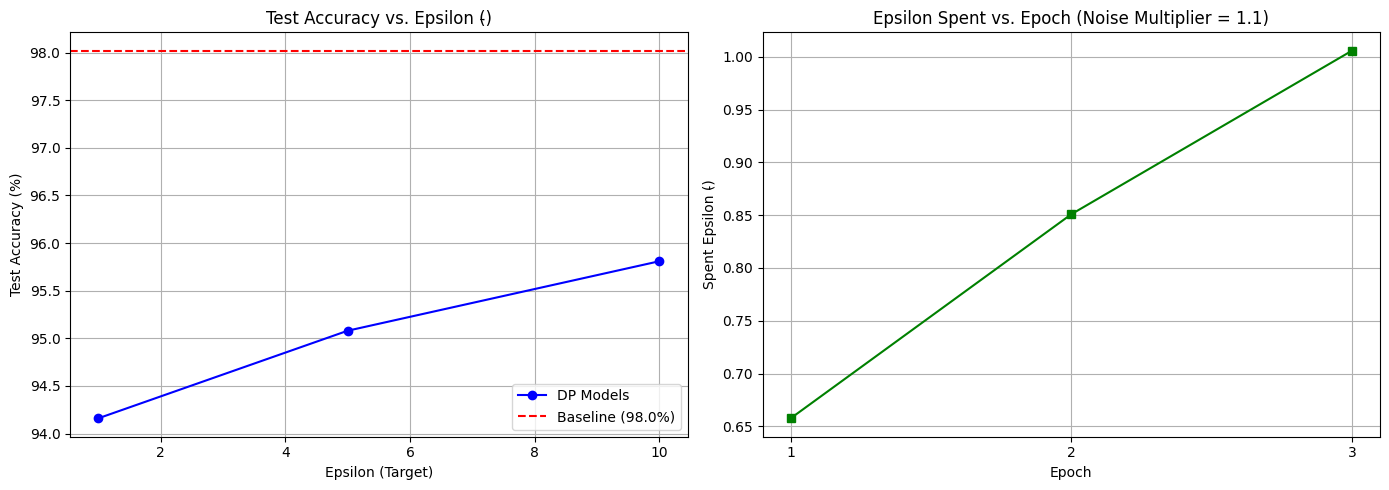

In [10]:
epsilons = [1.0, 5.0, 10.0]
acc_values = [dp_results[eps]["accuracy"] for eps in epsilons]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epsilons, acc_values, marker='o', linestyle='-', color='b', label='DP Models')
ax1.axhline(y=baseline_accuracy, color='r', linestyle='--', label=f'Baseline ({baseline_accuracy:.1f}%)')
ax1.set_title('Test Accuracy vs. Epsilon (̵)')
ax1.set_xlabel('Epsilon (Target)')
ax1.set_ylabel('Test Accuracy (%)')
ax1.legend()
ax1.grid(True)

epochs = [1, 2, 3]
ax2.plot(epochs, fixed_noise_epsilons, marker='s', linestyle='-', color='g')
ax2.set_title('Epsilon Spent vs. Epoch (Noise Multiplier = 1.1)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Spent Epsilon (̵)')
ax2.set_xticks(epochs)
ax2.grid(True)

plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png")
plt.show()

task 6

In [11]:
print("Expected Output — Part A: Accuracy at Different Privacy Budgets")
print(f"Baseline (no DP) : test accuracy {baseline_accuracy:.1f} %")
print("TARGET_EPS DELTA     CLIP(C) EPOCHS TEST_ACC EPS_SPENT")

for eps in [10.0, 5.0, 1.0]:
    print(f"{eps:<10} 1e-05     1.0     3      {dp_results[eps]['accuracy']:.1f} %  {dp_results[eps]['spent_epsilon']:.2f}")

print(f"Accuracy cost of strongest privacy (eps = 1) : {(dp_results[1.0]['accuracy'] - baseline_accuracy):.1f} %")
print("Plot saved : accuracy_vs_epsilon.png\n")

print("Expected Output — Part B: Privacy Accounting and Membership Check")
print("FIXED noise_multiplier = 1.1")
print("EPOCH  EPSILON_SPENT")

for i, eps_spent in enumerate(fixed_noise_epsilons, 1):
    print(f"{i:<6} {eps_spent:.2f}")


print("\nMEMBERSHIP CHECK (mean max-softmax confidence)")
print("MODEL       TRAIN   TEST    GAP")

print(f"Baseline    {baseline_train_conf:.3f}   {baseline_test_conf:.3f}   {baseline_gap:.3f}")
print(f"DP (eps=1)  {dp_train_conf:.3f}   {dp_test_conf:.3f}   {dp_gap:.3f}")

Expected Output — Part A: Accuracy at Different Privacy Budgets
Baseline (no DP) : test accuracy 98.0 %
TARGET_EPS DELTA     CLIP(C) EPOCHS TEST_ACC EPS_SPENT
10.0       1e-05     1.0     3      95.8 %  9.99
5.0        1e-05     1.0     3      95.1 %  5.00
1.0        1e-05     1.0     3      94.2 %  1.00
Accuracy cost of strongest privacy (eps = 1) : -3.9 %
Plot saved : accuracy_vs_epsilon.png

Expected Output — Part B: Privacy Accounting and Membership Check
FIXED noise_multiplier = 1.1
EPOCH  EPSILON_SPENT
1      0.66
2      0.85
3      1.01

MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL       TRAIN   TEST    GAP
Baseline    0.981   0.981   0.000
DP (eps=1)  0.970   0.971   -0.001
